In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

In [2]:
d_all = find_file(...) #load 2D data
# examples of how to use nddata
# -------- colon tells us to use the axis coordinates
d_all['Temperature':(270,280)] # a range of *temperature* -- because I used a colon
d_all['Temperature':270] # give me the spectrum with temperature closest to 270
# -------- comma tells us to just use a normal index (like numpy)
d_all['Temperature',0] # the first spectrum
d_all['Temperature',:3] # the first three spectra
# -------- if we just give the name of a dimension, we get the axis coordinates
d_all['Temperature'] # the array storing *all* the temperatures
d_all['Temperature'][2] # what is the third temperature?
for j in range(d_all.shape['Temperature']):
    d = d_all['Temperature',j]
    this_teperature = d_all['Temperature'][j] ### RS: Picking each temp individually?
    

TypeError: can only concatenate str (not "ellipsis") to str

first, load and store the data so we can
play with it

In [3]:
all_data = {}
label_strings = {}
colors = {}
for file_name,label_str,this_color in [
    ('221101_TEMPOSO4_w1_H2O_MarPrep_NovCap.DSC','$w_0$=1','blue'),
    ('220329_TEMPOSO4_RM3_H2O.DSC','$w_0$=5','green'),
    ('221101_TEMPOSO4_RM5_H2O.DSC','$w_0$=7','orange'),
    ('221101_TEMPOSO4_w10_H2O_MarPrep_NovCap.DSC','$w_0$=10','red'),
    ]:
    d = find_file(file_name, exp_type='francklab_esr/alec')
    label_strings[file_name] = label_str ##calling a data??
    colors[file_name] = this_color
    try:
        d.getaxis('harmonic')
        print("Harmonics found...")
        harmonics = True
        d_selected = d['harmonic',0]  ### RS ???
        d_selected2 = d['harmonic',0]  ### RS ???
    except ValueError:
        harmonics = False
        print("Harmonics not found...")
        d_selected = d  ###???
        d_selected2 = d ###???
    try:
        d.getaxis("'Time'")
        print("Time axis found...")
        time_resolved = True
        d_selected = d_selected["'Time'",0]
        d_selected2 = d_selected2["'Time'",-1]
    except ValueError:
        time_resolved = False
        print("Time axis not found...")
        d_selected = d_selected
    d_selected -= d_selected['$B_0$',0]
    if file_name == '220329_TEMPOSO4_RM3_H2O.DSC':
        reference_data = d_selected.C
    else:
        d_selected.setaxis('$B_0$', lambda b: b - 56.)
    all_data[file_name] = d_selected

Harmonics not found...
Time axis not found...
Harmonics found...
Time axis not found...
Harmonics not found...
Time axis not found...
Harmonics not found...
Time axis not found...


Loading data and selecting only first harmonics
also sort by temperature, since we've learned about pyspec bug with backwards data

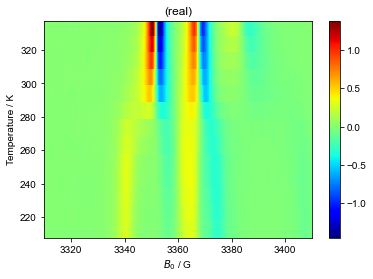

In [4]:
d_cooling = find_file("240226_TEMPOSO4_C10_W3_run1.DSC", exp_type="francklab_esr/romana") #cooling
# I should be able to do the following without the chunk-auto, but then sort freaks out -- this is a bug
d_cooling= d_cooling.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_cooling.reorder('Temperature').sort('Temperature')
d_cooling.pcolor()

## Check field ranges for the three lines

let's use 300 and 220 K as examples for where the peaks are located in the "high-temp" vs. "low-temp" limits

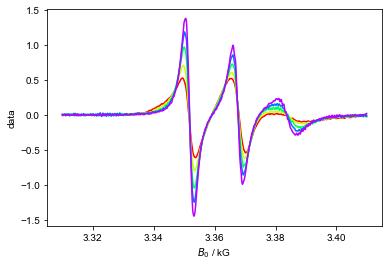

In [5]:
d_cooling['Temperature':(285,None)]

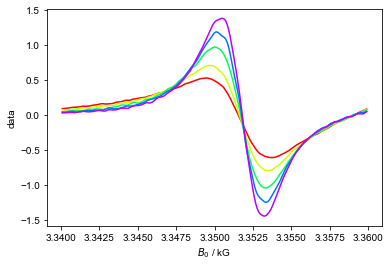

In [6]:
d_cooling['Temperature':(285,None)]['$B_0$':(3340,3360)]

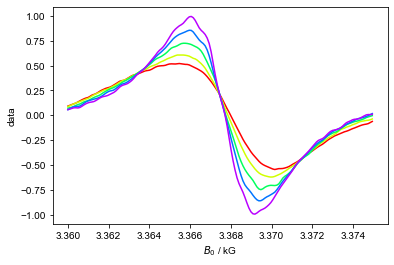

In [7]:
d_cooling['Temperature':(285,None)]['$B_0$':(3360,3375)]

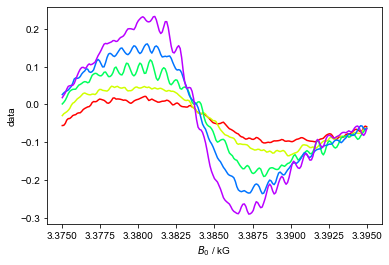

In [8]:
d_cooling['Temperature':(285,None)]['$B_0$':(3375,3395)]

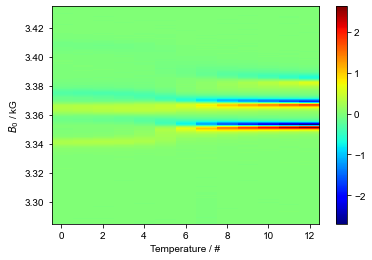

In [9]:
d_reheating = find_file("240226_TEMPOSO4_C10_W3_run2.DSC", exp_type="francklab_esr/romana") #reheating subsequently
d_reheating = d_reheating["harmonic", 0]
d_reheating

In [10]:
print(d_cooling["Temperature":273]['$B_0$':3340])


array(0.21353359)
		+/-None
	dimlabels=[]
	axes={}



In [11]:
all_data= d_cooling['Temperature':(285,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
correlation_time = {}
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        peak_A_range = (3340,3360)
        peak_B_range = (3360,3375)
        peak_C_range = (3375,3395)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            #### RS: 20 to 36. What's happening here?
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda()
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=1e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item()
            min_B0 = peak.C.argmin()['$B_0$']
            print(max_B0)
            peak_data[peak_name+'max']=peak['$B_0$':max_B0].item() ##??
            peak_data[peak_name+'min']=peak['$B_0$':min_B0].item() ##??
            peak_data[peak_name+'maxB0']=max_B0
            peak_data[peak_name+'minB0']=min_B0
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
        fl.next('pub_fig',figsize=(6,6/(1+sqrt(5))*2)) ##fig size why strange?
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter purpose? 
        plt.gca().text(
                3500,
                x_counter,
                label_str,
                transform = plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        annotate('%s'%label_str,(3.51,x_counter+0.1),color=this_color)
        x_counter += 1.1
        xlim(3375,3550)
        j_counter += 1
        print(eval("(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin)))",{'sqrt':sqrt},peak_data))
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        print("correlation time is",tau_c)
        correlation_time[file_name] = tau_c 
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)
    savefig('figures/RM_ESR_stack.pdf',
            transparent=True,
            bbox_inches='tight',
            pad_inches=0.1,
            dpi=400)

TypeError: 'dict' object is not an iterator

In [ ]:
print(r'''\begin{tabular}{cc}
$w_0$ & $\tau_c/\text{ns}$\\
\hline\hline
      '''
      +'\\\\\n'.join([label_strings[j].replace('$w_0$=','') +' & %0.2g'%(correlation_time[j]/1e-9) for j in [
            '221101_TEMPOSO4_w1_H2O_MarPrep_NovCap.DSC',
            '220329_TEMPOSO4_RM3_H2O.DSC',
            '221101_TEMPOSO4_RM5_H2O.DSC',
            '221101_TEMPOSO4_w10_H2O_MarPrep_NovCap.DSC',
            ]])
      +r'''\\ \hline
\end{tabular}
'''
      )

In [ ]:
R_h = 3.35e-9/2
T = 273+20
eta = 0.91e-3 # 1 cP = 1e-3 Pa*s
4*pi*R_h**3*eta/(3*k_B*T)/1e-9

In [ ]:
(0.29+1.1)/2

In [ ]:
3.35/2

In [ ]:
0.175+1.5

In [ ]:
f = 11.71e6
w = 2*pi*f
w

In [ ]:
c = 330e-12
L = 1/((w**2)*c)
L